In [5]:
!pip install finance-datareader
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
samsung=fdr.DataReader('005930','2016')
print(samsung.head(10))

             Open   High    Low  Close  Volume    Change
Date                                                    
2016-01-04  25200  25200  24100  24100  306939 -0.043651
2016-01-05  24040  24360  23720  24160  216002  0.002490
2016-01-06  24160  24160  23360  23500  366752 -0.027318
2016-01-07  23320  23660  23020  23260  282388 -0.010213
2016-01-08  23260  23720  23260  23420  257763  0.006879
2016-01-11  23120  23320  22920  23040  241277 -0.016225
2016-01-12  22960  23320  22880  22920  206283 -0.005208
2016-01-13  23060  23180  22960  22960  143316  0.001745
2016-01-14  22620  22840  22620  22760  209022 -0.008711
2016-01-15  22800  23040  22480  22640  209464 -0.005272


In [8]:
openValues=samsung[['Open']]

In [10]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler(feature_range=(0,1))
scaled=scaler.fit_transform(openValues)
print(scaled)

[[0.06765101]
 [0.06453691]
 [0.06485906]
 ...
 [0.57181208]
 [0.48322148]
 [0.50255034]]


In [11]:
TEST_SIZE=200
train_data=scaled[:-TEST_SIZE]
test_data=scaled[-TEST_SIZE:]

In [30]:
def make_sample(data,window):
  train=[]
  target=[]
  for i in range(len(data)-window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train),np.array(target)

X_train, y_train=make_sample(train_data,30)


In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

model=Sequential()
model.add(LSTM(16, input_shape=(X_train.shape[1],1),
               activation='tanh',
               return_sequences=False))
model.add(Dense(1))

In [32]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train,y_train, epochs=100, batch_size=16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 8.6051e-04
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.6712e-05
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.3995e-05
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.1444e-05
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.9114e-05
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.0364e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.9334e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.7896e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.5793e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.6801e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.5745e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3717e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 4.3829e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss

In [33]:
X_test, y_test=make_sample(test_data,30)
pred=model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


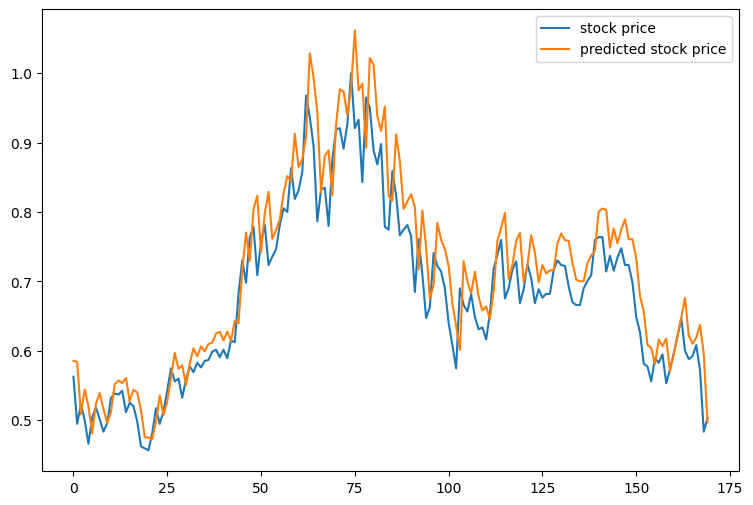

In [34]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 6))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()